# Phase 04 · Notebook 2: control networks

## Erdős–Rényi and the configuration model

These two networks are the yardstick of the project. They share with the connectome everything that can be shared. The number of neurons and of connections of each polarity is the same, and so are the distribution of weights, the input layer, the stimuli, the neuron model, the plasticity and the operating point. They differ **only in how they are wired**. If the biological network wins, the advantage cannot come from anywhere else.

We use two controls, from less to more demanding.

- **Erdős–Rényi** places the same number of directed connections of each sign uniformly at random, with no self-connections and no duplicates (Erdős & Rényi, 1959). It keeps the density and nothing else.
- The **configuration model** also keeps the **degree sequence** (Molloy & Reed, 1995; Newman et al., 2001). Every neuron keeps, almost exactly, how many connections enter it and leave it, while their endpoints are reshuffled. It is the strict control, because it rules out that the biological advantage comes down to a few highly connected neurons. A recent preprint, not yet peer reviewed, argues that topology advantages reported for connectome-constrained networks can vanish under degree-preserving controls (Dhiman, 2026). That is why we treat this control as the decisive one.

The controls draw their weights from the connectome's own weights for each polarity, so the three networks differ only in their wiring. Phase 02 built both controls and described their structure. This notebook reports how they do on the task.

### Background for readers new to the project

This project asks whether a spiking network wired like an auditory circuit of the fruit fly learns a sound task better than networks of the same size with artificial wiring. The circuit is that of **Johnston's organ** (JO), the fly's ear, taken from the FlyWire **connectome**, the map of all the neurons of the fly brain and of the connections between them (Dorkenwald et al., 2024).

The sound is the **courtship song**, a train of brief song pulses that a male produces by vibrating one wing. The time between consecutive pulses is the **inter-pulse interval** (IPI), one of the cues a female uses to recognize males of her species (Bennet-Clark & Ewing, 1969). The task is to tell apart five songs whose IPIs go from 25 to 65 ms. **Spike encoding** turns each song into spikes for the input layer of the network. A **gammatone filterbank** first splits the sound into 32 frequency bands (Patterson et al., 1992), and an **inner-hair-cell model**, named after the cells that do this in the mammalian ear, turns each band into a firing rate that drives random spikes. The [audio-encoding notebook](01-audio-encoding.ipynb) builds and checks that chain.

In a **spiking neural network** (SNN) neurons communicate with brief electrical events called **spikes**. Ours are **leaky integrate-and-fire** (LIF) neurons with **three synaptic channels**, one excitatory, one inhibitory and one modulatory. Each neuron adds up the current of its channels, leaks it slowly and fires when its voltage crosses a threshold. The networks learn with **spike-timing-dependent plasticity** (STDP), a local rule that strengthens a connection when the sending neuron fires just before the receiving one and weakens it when it fires just after (Song et al., 2000). **Winner-take-all** (WTA) inhibition, a pool of inhibitory neurons, holds the network back when many neurons fire at once, so that a few of them specialize.

The **linear readout** is a logistic regression that names the song from the spike count of each neuron. With five songs the **chance level** is 0.200. The **input-only ceiling**, the accuracy of the same readout applied to the input layer alone, is 0.223. What a network achieves above that ceiling is what the network computes.

The design has six experimental **arms**: three wirings, each run with static weights and with STDP + WTA. Each arm runs with several **seeds**, the numbers that fix the random generators so that a run can be repeated exactly. A **paired comparison** sets two arms side by side seed by seed, so that only the factor of interest changes. The **effect size**, Cohen's d, measures a difference between arms in units of their standard deviation (Cohen, 1988/2013). The **spikes per correct classification**, all the spikes the network fires during the test divided by the number of correct answers, measure what each answer costs.

This notebook reports the four control arms. The connectome arms are in [notebook 3](03-connectome-static.ipynb) (static) and [notebook 4](04-connectome-stdp.ipynb) (with STDP + WTA), where the six arms are compared together.

## 0. Environment and results

This notebook runs no simulation. The cell loads the subgraph, the operating point calibrated in phase 03 and the stored results of the experiments, `outputs/results.json` and `outputs/extra_seeds.json`, which `run_experiments.py` and `extra_seeds.py` produce. It also defines two helpers. `summary` returns the mean and standard deviation of one metric for one arm, and `arm_table` lists the metrics of every seed of an arm.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from snnlib import audio as A, evaluation as E, graph, network as NET, FIGURES
from snnlib.evaluation import IPIS, PAIRS, WINDOWS_MS

FIGURES.mkdir(exist_ok=True)
OUT_DIR = Path('outputs')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':150,'savefig.bbox':'tight',
                     'axes.titleweight':'bold','font.size':10})
BLUE, RED, GREEN, PURPLE, GRAY = '#2E86AB','#C73E1D','#3CAEA3','#7B68A6','#8A948F'

C = graph.load()
OP = json.loads((Path('..')/'03-data-preparation'/'outputs'/'operating_point.json').read_text())
RES = E.load_results()   # joins results.json and extra_seeds.json
CHANCE = 1/len(IPIS)

def summary(arm, col='accuracy'):
    d = RES[RES.arm==arm][col]
    return d.mean(), d.std()

def arm_table(arm):
    d = RES[RES.arm==arm]
    rows = []
    for _, r in d.iterrows():
        rows.append(dict(seed=int(r.seed), accuracy=r.accuracy,
                         rate_hz=r.mean_rate_hz, spikes_per_correct=r.spikes_per_correct,
                         selectivity=r.selectivity, coverage=r.coverage_pct))
    t = pd.DataFrame(rows).set_index('seed')
    return pd.concat([t, t.agg(['mean','std'])]).round(3)

## 1. The control topologies

Before looking at any result, we check that the controls are what they claim to be. They should have the same number of connections (`edges`, the edges of the graph), the same split of polarities and the same weights, and their structure should be scrambled to the extent each control intends. The table builds each wiring with seed 0. `mean_weight` is the mean normalized weight, and `out_degree_corr` is the correlation between each neuron's out-degree (its number of outgoing connections) in the control and in the connectome.

In [2]:
rows=[]
for topo in ['connectome','er','configuration']:
    wiring = C.wiring(topo, seed=0)
    pre = np.concatenate([v[0] for v in wiring.values()])
    w = np.concatenate([v[2] for v in wiring.values()])
    gs_bio = np.bincount(C.pre, minlength=C.N); gs = np.bincount(pre, minlength=C.N)
    rows.append(dict(topology=topo, edges=len(pre),
                     **{k:int(v.sum()) for k,v in C.mask.items()},
                     mean_weight=w.mean(),
                     out_degree_corr=float(np.corrcoef(gs_bio,gs)[0,1])))
pd.DataFrame(rows).set_index('topology').round(4)

,edges,Excitatory,Inhibitory,Modulatory,mean_weight,out_degree_corr
topology,,,,,,
connectome,20059,8512,11437,110,1.0000,1.0000
er,20059,8512,11437,110,0.9943,0.0142
configuration,20059,8512,11437,110,0.9985,1.0000


By construction, the three networks have exactly 20,059 connections, with the same split of polarities (8,512 excitatory, 11,437 inhibitory and 110 modulatory). The mean weight of the controls, 0.9943 and 0.9985, is close to the 1.0000 of the connectome because their weights are drawn from the connectome's own. The configuration model reproduces the out-degree sequence almost exactly (correlation 1.0000 to four decimals), while Erdős–Rényi wipes it out (0.0142).

## 2. Operating point

Before any comparison, phase 03 calibrated every arm to the same **operating point**, a mean firing rate of about 10 Hz before learning. A bisection search tuned the input gain `w_input`, the strength with which each input spike drives its neuron, separately for each arm. Each topology needs a different gain to reach that rate, and the gain itself is informative. The random network spreads excitation more easily than the biological one. All three have the same number of inhibitory connections, so the difference comes from how the connections are arranged; phase 02 found the connectome much more modular.

In [3]:
op = pd.DataFrame(OP['arms']).T
op[['w_input','rate','rate_sd']] = op[['w_input','rate','rate_sd']].astype(float).round(3)
print(f'Calibration target: {OP["target_hz"]} Hz  |  wta_inh = {OP["wta_inh"]}')
op[['topology','stdp','w_input','rate','rate_sd']]

Calibration target: 10.0 Hz  |  wta_inh = 0.6


,topology,stdp,w_input,rate,rate_sd
connectome_static,connectome,False,10.075,10.412,0.459
connectome_stdp,connectome,True,17.556,10.064,0.224
er_static,er,False,5.088,9.831,1.581
er_stdp,er,True,15.062,10.161,0.688
configuration_static,configuration,False,6.334,10.143,0.910
configuration_stdp,configuration,True,15.062,10.161,0.690


All six arms sit close to the target, between 9.83 and 10.41 Hz. The static Erdős–Rényi network needs only 5.088 nA of input gain, about half the 10.075 nA of the static connectome, to reach the same rate. The arms with plasticity need more gain (15.062 nA for both controls, 17.556 nA for the connectome) because they run with the WTA inhibition switched on. Without this matching, a network that fires more would hand more spikes to the readout and look better for that reason alone.

## 3. Classification results

The task is to say which of the five inter-pulse intervals is playing, so the chance level is 1/5 = 0.200. The readout is a logistic regression (Pedregosa et al., 2011) trained on the responses of the neurons that do **not** receive the stimulus, the 1,116 neurons outside the input layer. The weights of the network are frozen while the readout is trained, and the readout is tested on Poisson realizations it has never seen. Means and standard deviations are taken over seeds, 5 in the static arms and 15 in the arms with STDP + WTA. The table at the end lists every seed of Erdős–Rényi with STDP + WTA. For each seed it gives the accuracy, the mean firing rate, the spikes per correct classification, the selectivity and the coverage.

In [4]:
for arm in ['er_static','er_stdp','configuration_static','configuration_stdp']:
    m,s = summary(arm)
    print(f'{arm:26s} accuracy = {m:.3f} ± {s:.3f}')
print(f'\nChance = {CHANCE:.3f}')
print()
print('Erdős–Rényi with STDP + WTA, per-seed detail:')
arm_table('er_stdp')

er_static                  accuracy = 0.444 ± 0.057
er_stdp                    accuracy = 0.443 ± 0.080
configuration_static       accuracy = 0.604 ± 0.050
configuration_stdp         accuracy = 0.768 ± 0.148

Chance = 0.200

Erdős–Rényi with STDP + WTA, per-seed detail:


,accuracy,rate_hz,spikes_per_correct,selectivity,coverage
0,0.510,27.469,16683.627,0.915,14.022
1,0.390,32.888,26120.462,0.911,14.541
2,0.500,29.833,18481.440,0.931,10.601
3,0.390,39.543,31406.462,0.918,8.947
4,0.350,36.138,31981.886,0.923,8.621
5,0.370,41.547,34781.865,0.907,9.686
6,0.410,29.141,22015.390,0.907,14.297
7,0.450,27.012,18593.156,0.920,12.615
8,0.340,39.121,35640.500,0.900,11.925
9,0.530,28.715,16782.113,0.922,12.963


Both controls are well above chance. Plasticity does nothing for Erdős–Rényi (0.444 ± 0.057 static, 0.443 ± 0.080 with STDP + WTA). The configuration model gains from it (0.604 ± 0.050 to 0.768 ± 0.148), with a large spread between seeds, and the gain is not significant ([notebook 4](04-connectome-stdp.ipynb)).

The per-seed table shows what plasticity does to the random network. Its mean rate climbs to 33.94 Hz, more than three times the operating point it started from, and each correct answer costs 25,175 spikes. Learning makes this network fire much more without making it more accurate. **Selectivity** (0 when all neurons respond alike, 1 when a single neuron responds) and **coverage** (the percentage of the readout neurons that fire at least once) are defined in [notebook 4](04-connectome-stdp.ipynb), where the six arms are compared on them.

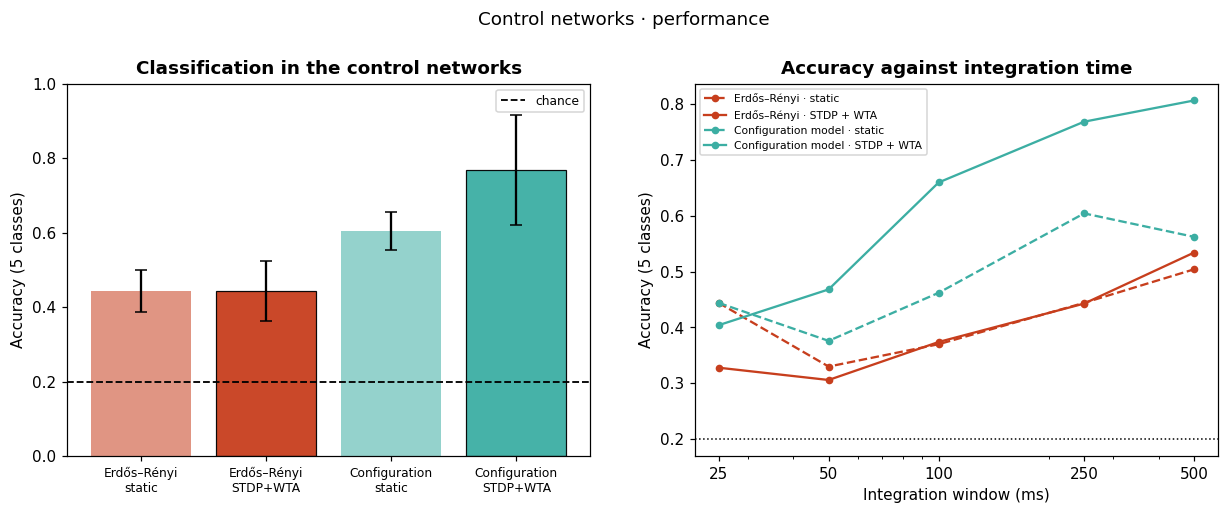

In [5]:
fig, ax = plt.subplots(1,2, figsize=(13.5,4.4))
arms = ['er_static','er_stdp','configuration_static','configuration_stdp']
labels = ['Erdős–Rényi\nstatic','Erdős–Rényi\nSTDP+WTA','Configuration\nstatic','Configuration\nSTDP+WTA']
cols = [RED,RED,GREEN,GREEN]
m = [summary(b)[0] for b in arms]; s = [summary(b)[1] for b in arms]
for k,(mi,si,ci,al) in enumerate(zip(m, s, cols, [.55,.95,.55,.95])):
    ax[0].bar(k, mi, yerr=si, color=ci, alpha=al, capsize=4,
              edgecolor='k' if al > .9 else 'none', linewidth=.8)
ax[0].axhline(CHANCE, color='k', ls='--', lw=1.2, label='chance')
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(labels, fontsize=8)
ax[0].set_ylabel('Accuracy (5 classes)'); ax[0].set_ylim(0,1); ax[0].legend(fontsize=8)
ax[0].set_title('Classification in the control networks')

for b,c,ls,lab in zip(arms, cols, ['--','-','--','-'],
                      ['Erdős–Rényi · static','Erdős–Rényi · STDP + WTA',
                       'Configuration model · static','Configuration model · STDP + WTA']):
    curves = np.array([list(r.values()) for r in RES[RES.arm==b].accuracy_vs_window])
    ax[1].plot(WINDOWS_MS, curves.mean(axis=0), ls, color=c, marker='o', ms=4,
               label=lab)
ax[1].axhline(CHANCE, color='k', ls=':', lw=1)
ax[1].set_xscale('log'); ax[1].set_xticks(WINDOWS_MS); ax[1].set_xticklabels(WINDOWS_MS)
ax[1].set_xlabel('Integration window (ms)'); ax[1].set_ylabel('Accuracy (5 classes)')
ax[1].legend(fontsize=7); ax[1].set_title('Accuracy against integration time')
fig.suptitle('Control networks · performance', y=1.03)
fig.savefig(FIGURES/'04-control-networks-performance.png'); plt.show()

Left panel: five-class accuracy of the four control arms, with the chance line. Right panel: accuracy against the **integration window**, the length of the response (from 25 to 500 ms) that the readout counts before deciding. The main results use 250 ms. The configuration model with STDP keeps improving up to the longest window (0.806 at 500 ms). Both Erdős–Rényi arms stay low across every window and never pass 0.534.

## 4. Difficulty gradient

Here the readout only chooses between **two** songs, not five, so the chance level of this table is **0.500**, and its numbers cannot be compared with the five-class accuracies. The five pairs come from the same set of responses, by restricting the readout to two classes. No extra simulation is needed.

The pairs are ordered by their **relative** difference, which is what makes a pair easy or hard. `Very easy` is 25 vs 65 ms (40 ms apart, 160 % of the shorter interval), and `Very hard` is 45 vs 55 ms (10 ms apart, only 22 %). `Hard`, 35 vs 45 ms, is also 10 ms apart but differs by 29 %. Ordering by proportion follows Weber's law for time intervals (Gibbon, 1977). Each cell gives the mean ± the standard deviation over seeds (population formula).

In [6]:
rows=[]
for b in arms:
    d = RES[RES.arm==b]
    row = {'arm': b}
    for name,_,_ in PAIRS:
        v = np.array([p[name] for p in d.pair_accuracy])
        row[name] = f'{v.mean():.3f}±{v.std():.3f}'
    rows.append(row)
pd.DataFrame(rows).set_index('arm')

,Very easy,Easy,Medium,Hard,Very hard
arm,,,,,
er_static,0.920±0.056,0.910±0.073,0.845±0.097,0.630±0.066,0.650±0.089
er_stdp,0.933±0.058,0.905±0.083,0.848±0.086,0.672±0.085,0.682±0.107
configuration_static,0.980±0.019,0.995±0.010,0.970±0.019,0.900±0.045,0.785±0.098
configuration_stdp,0.990±0.031,0.995±0.014,0.983±0.036,0.950±0.074,0.927±0.148


Every control does better on easy pairs than on hard ones, as expected. The configuration model with STDP + WTA keeps 0.950 and 0.927 on the two hardest pairs. Erdős–Rényi stays between 0.630 and 0.682 there, a little above the 0.500 of chance. In both Erdős–Rényi arms the hardest pair (45 vs 55 ms) comes out slightly better than the `Hard` pair (35 vs 45 ms), so for this network the order predicted by the relative difference does not hold. Its accuracies on the two hard pairs are close to each other and to chance, which leaves little room for any ordering.

## 5. What these controls contribute

The configuration model is the control that really tests the connectome. It keeps the degree distribution, so any biological advantage that survives the comparison cannot be explained by uneven connectivity. It has to come from how the connections are organized.

The full comparison against the biological topology is in [notebook 4](04-connectome-stdp.ipynb), which brings the six arms together. The [results of this phase](results.md) summarize the outcome.

## References

- Bennet-Clark, H. C., & Ewing, A. W. (1969). Pulse interval as a critical parameter in the courtship song of *Drosophila melanogaster*. *Animal Behaviour, 17*(4), 755–759. https://doi.org/10.1016/S0003-3472(69)80023-0
- Cohen, J. (2013). *Statistical power analysis for the behavioral sciences* (2nd ed.). Routledge. https://doi.org/10.4324/9780203771587 (Original work published 1988)
- Dhiman, N. (2026). *Topological sensitivity in connectome-constrained neural networks* (arXiv:2604.04033) [Preprint]. arXiv. https://doi.org/10.48550/arXiv.2604.04033
- Dorkenwald, S., Matsliah, A., Sterling, A. R., Schlegel, P., Yu, S.-c., McKellar, C. E., Lin, A., Costa, M., Eichler, K., Yin, Y., Silversmith, W., Schneider-Mizell, C., Jordan, C. S., Brittain, D., Halageri, A., Kuehner, K., Ogedengbe, O., Morey, R., Gager, J., . . . The FlyWire Consortium. (2024). Neuronal wiring diagram of an adult brain. *Nature, 634*(8032), 124–138. https://doi.org/10.1038/s41586-024-07558-y
- Erdős, P., & Rényi, A. (1959). On random graphs I. *Publicationes Mathematicae Debrecen, 6*(3–4), 290–297. https://doi.org/10.5486/PMD.1959.6.3-4.12
- Gibbon, J. (1977). Scalar expectancy theory and Weber’s law in animal timing. *Psychological Review, 84*(3), 279–325. https://doi.org/10.1037/0033-295X.84.3.279
- Molloy, M., & Reed, B. (1995). A critical point for random graphs with a given degree sequence. *Random Structures & Algorithms, 6*(2–3), 161–180. https://doi.org/10.1002/rsa.3240060204
- Newman, M. E. J., Strogatz, S. H., & Watts, D. J. (2001). Random graphs with arbitrary degree distributions and their applications. *Physical Review E, 64*(2), Article 026118. https://doi.org/10.1103/PhysRevE.64.026118
- Patterson, R. D., Robinson, K., Holdsworth, J., McKeown, D., Zhang, C., & Allerhand, M. (1992). Complex sounds and auditory images. In Y. Cazals, L. Demany, & K. Horner (Eds.), *Auditory physiology and perception* (pp. 429–446). Pergamon. https://doi.org/10.1016/B978-0-08-041847-6.50054-X
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- Song, S., Miller, K. D., & Abbott, L. F. (2000). Competitive Hebbian learning through spike-timing-dependent synaptic plasticity. *Nature Neuroscience, 3*(9), 919–926. https://doi.org/10.1038/78829